# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

This notebook reuses the pipeline in `team_notebook.ipynb` so the numbers here are the same ones we will present.
It reruns the whole team notebook (including the live weather API call) and then reports each question.

In [1]:
%%capture team_run
# Run the full team notebook (cleaning, SKU map, live weather API, join) without echoing its output.
# Everything below reuses its tables: tx, stores, sku_map, weather, store_day, sw, BASE_START, BASE_END, LANDFALL.
%run team_notebook.ipynb

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [2]:
SURGE_START, SURGE_END = '2024-09-21', '2024-09-25'

daily_units = tx.groupby('date')['quantity'].sum()
daily_txn = tx.groupby('date').size()

base_units = daily_units.loc[BASE_START:BASE_END].mean()
surge_units = daily_units.loc[SURGE_START:SURGE_END].mean()
base_txn = daily_txn.loc[BASE_START:BASE_END].mean()
surge_txn = daily_txn.loc[SURGE_START:SURGE_END].mean()

q1_multiple = surge_units / base_units

print(f'baseline window: {BASE_START} to {BASE_END} ({len(daily_units.loc[BASE_START:BASE_END])} days)')
print(f'surge window:    {SURGE_START} to {SURGE_END} ({len(daily_units.loc[SURGE_START:SURGE_END])} days), ends the day before landfall')
print()
print(f'units per day:        baseline {base_units:,.0f} | surge {surge_units:,.0f} | multiple {q1_multiple:.2f}x')
print(f'transactions per day: baseline {base_txn:,.0f} | surge {surge_txn:,.0f} | multiple {surge_txn / base_txn:.2f}x')
print(f'peak single day: {daily_units.idxmax():%b %d} at {daily_units.max() / base_units:.2f}x baseline units')

baseline window: 2024-09-01 to 2024-09-14 (14 days)
surge window:    2024-09-21 to 2024-09-25 (5 days), ends the day before landfall

units per day:        baseline 1,109 | surge 3,190 | multiple 2.88x
transactions per day: baseline 578 | surge 1,599 | multiple 2.77x
peak single day: Sep 25 at 3.57x baseline units


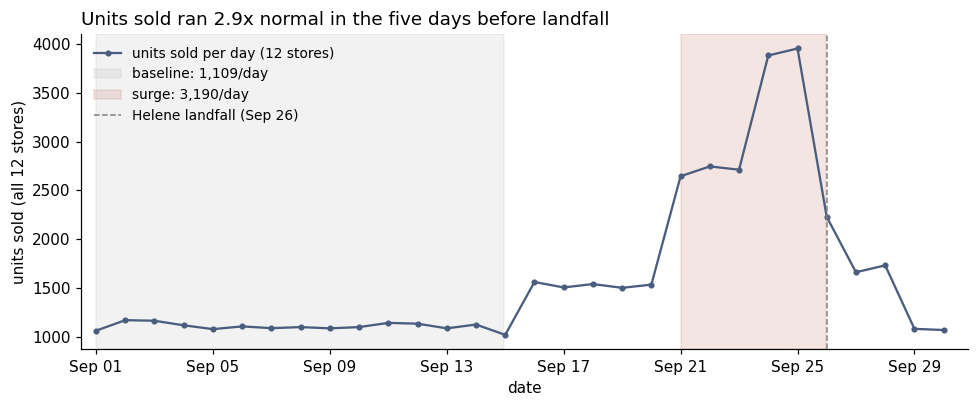

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(daily_units.index, daily_units.values, marker='o', ms=3, color='#4a5d7e', label='units sold per day (12 stores)')
ax.axvspan(pd.Timestamp(BASE_START), pd.Timestamp(BASE_END) + pd.Timedelta(hours=23), color='gray', alpha=0.10, label=f'baseline: {base_units:,.0f}/day')
ax.axvspan(pd.Timestamp(SURGE_START), pd.Timestamp(SURGE_END) + pd.Timedelta(hours=23), color='#b4553f', alpha=0.15, label=f'surge: {surge_units:,.0f}/day')
ax.axvline(LANDFALL, ls='--', color='gray', lw=1, label='Helene landfall (Sep 26)')
ax.set_title(f'Units sold ran {q1_multiple:.1f}x normal in the five days before landfall', loc='left', fontsize=12)
ax.set_xlabel('date')
ax.set_ylabel('units sold (all 12 stores)')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 31, 4)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 20:00'))
ax.legend(frameon=False, fontsize=9, loc='upper left')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** Against a Sep 1-14 baseline of about 1,110 units a day, our 12 Florida stores sold about 3,190 units a day from Sep 21-25, **2.9x normal**, and peaked at 3.6x on Sep 25, the day before Helene made landfall.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [4]:
n_skus = tx['sku'].nunique()
n_products = tx['product'].nunique()
family = sku_map.groupby('product')['sku'].size().idxmax()
family_skus = sorted(sku_map.loc[sku_map['product'] == family, 'sku'])

# Consolidation must only relabel rows, never add or lose units.
units_by_sku = tx.groupby('sku')['quantity'].sum()
units_by_product = tx.groupby('product')['quantity'].sum()
assert units_by_sku.sum() == units_by_product.sum() == tx['quantity'].sum()
for product, skus in sku_map.groupby('product')['sku']:
    assert units_by_sku.reindex(skus, fill_value=0).sum() == units_by_product[product], product
print(f'unit totals unchanged: {units_by_sku.sum():,} units by SKU == {units_by_product.sum():,} units by product (checked per product too)')
print()
print(f'distinct SKUs: {n_skus} -> canonical products: {n_products}')
print(f'largest family: {family}, {len(family_skus)} SKUs: {family_skus}')
print()

# Before and after: the same top-5 question asked of SKUs vs products.
before = units_by_sku.nlargest(5).rename('units').to_frame()
before['product'] = before.index.map(sku_map.set_index('sku')['product'])
after = units_by_product.nlargest(5).rename('units').to_frame()
print('top 5 BEFORE consolidation (by SKU):')
print(before)
print()
print('top 5 AFTER consolidation (by product):')
print(after)
print()
print(f'{family} per SKU (none would make a top-5 list alone):')
print(units_by_sku.reindex(family_skus).sort_values(ascending=False).to_string())
print()

# Sanity check on the surprise: does each SKU surge on its own, or is one bad mapping inflating the family?
sku_daily = tx[tx['product'] == family].pivot_table(index='date', columns='sku', values='quantity', aggfunc='sum').fillna(0)
sku_peak = (sku_daily / sku_daily.loc[BASE_START:BASE_END].mean()).max().round(1)
print(f'{family} peak multiple per SKU (vs Sep 1-14):', sku_peak.to_dict())

unit totals unchanged: 47,897 units by SKU == 47,897 units by product (checked per product too)



distinct SKUs: 45 -> canonical products: 20
largest family: Pop-Tarts Strawberry, 4 SKUs: ['POPTART-STRAW', 'PT-12', 'PT_STRAWBERRY', 'SKU#459812']

top 5 BEFORE consolidation (by SKU):
           units                product
sku                                    
WTR_24PK    1758  Bottled Water 24-Pack
WATER24PK   1657  Bottled Water 24-Pack
WTR-24      1622  Bottled Water 24-Pack
BATT-100    1432    AA Batteries 4-Pack
BAT-AA4     1427    AA Batteries 4-Pack

top 5 AFTER consolidation (by product):
                       units
product                     
Bottled Water 24-Pack   5037
Pop-Tarts Strawberry    5005
AA Batteries 4-Pack     4154
LED Flashlight          2814
Emergency Candles       2546

Pop-Tarts Strawberry per SKU (none would make a top-5 list alone):
sku
PT-12            1332
POPTART-STRAW    1239
PT_STRAWBERRY    1230
SKU#459812       1204

Pop-Tarts Strawberry peak multiple per SKU (vs Sep 1-14): {'POPTART-STRAW': 7.5, 'PT-12': 11.6, 'PT_STRAWBERRY': 9.0, 'SKU#4598

**Q2 answer:** Our 45 raw SKUs collapse to **20 canonical products** with no units gained or lost (47,897 either way). The largest family is strawberry Pop-Tarts, split across 4 SKUs of about 1,200-1,330 units each, so no single Pop-Tarts SKU makes a top-5 list. Consolidated, it is 5,005 units and the **#2 product**, just behind bottled water (5,037), while the SKU top 5 shows water three times.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

API: https://archive-api.open-meteo.com/v1/archive
data source: LIVE (every row fetched from Open-Meteo this run, no fallback file): True
weather pulled for 12 stores, 30 days each, every day 24 local hours: True

join rows: sales store-days before = 360 | weather store-days = 360 | after inner join = 360
rows preserved: True | join validated one_to_one on (store_id, local date)
units before join = 47,897 | after join = 47,897

correlation of store sales index (units / own Sep 1-14 avg) with max wind gust, by lag:
-3   -0.21
-2   -0.12
-1    0.01
 0    0.18
 1    0.50
 2    0.71
 3    0.56

same day (lag 0): r = 0.18 over 30 days x 12 stores = 360 store-days
best (lag +2, wind 2 days after sales): r = 0.71 over 28 days x 12 stores = 336 store-days


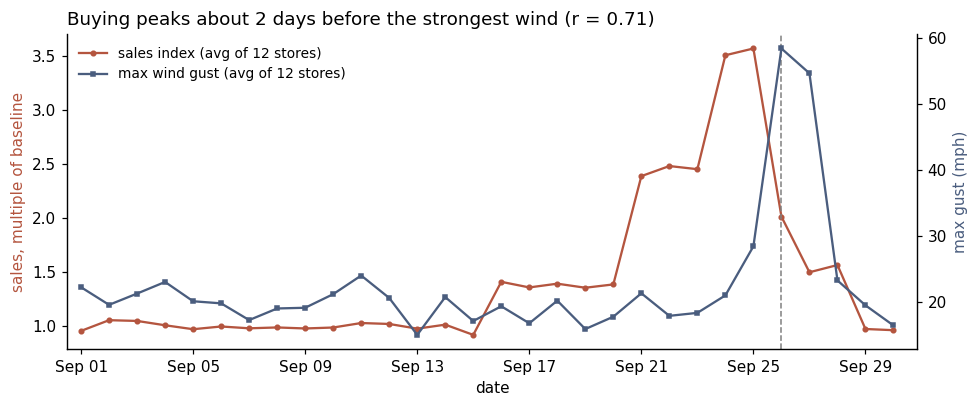

In [5]:
print('API:', BASE_URL)
print('data source: LIVE (every row fetched from Open-Meteo this run, no fallback file):', (weather['source'] == 'open-meteo: ' + BASE_URL).all())
print(f'weather pulled for {weather["store_id"].nunique()} stores, {weather["date"].nunique()} days each, every day 24 local hours: {(weather["hours"] == 24).all()}')
print()

rows_before = len(store_day)
rows_after = len(sw)
q3_join_rows_preserved = rows_before == rows_after == len(weather)
print(f'join rows: sales store-days before = {rows_before} | weather store-days = {len(weather)} | after inner join = {rows_after}')
print('rows preserved:', q3_join_rows_preserved, '| join validated one_to_one on (store_id, local date)')
print(f'units before join = {store_day["units"].sum():,} | after join = {sw["units"].sum():,}')
assert q3_join_rows_preserved and store_day['units'].sum() == sw['units'].sum()
print()

best_lag = lag_corr.idxmax()
lagged = sw.groupby('store_id')['max_gust_mph'].shift(-best_lag)
pairs = sw['units_index'].notna() & lagged.notna()
q3_days = sw.loc[pairs, 'date'].nunique()
print('correlation of store sales index (units / own Sep 1-14 avg) with max wind gust, by lag:')
print(lag_corr.round(2).to_string())
print()
print(f'same day (lag 0): r = {lag_corr[0]:.2f} over {sw["date"].nunique()} days x 12 stores = {len(sw)} store-days')
print(f'best (lag +{best_lag}, wind {best_lag} days after sales): r = {lag_corr[best_lag]:.2f} over {q3_days} days x 12 stores = {pairs.sum()} store-days')

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(statewide.index, statewide['units_index'], marker='o', ms=3, color='#b4553f', label='sales index (avg of 12 stores)')
ax.set_ylabel('sales, multiple of baseline', color='#b4553f')
ax2 = ax.twinx()
ax2.plot(statewide.index, statewide['max_gust_mph'], marker='s', ms=3, color='#4a5d7e', label='max wind gust (avg of 12 stores)')
ax2.set_ylabel('max gust (mph)', color='#4a5d7e')
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.set_title(f'Buying peaks about {best_lag} days before the strongest wind (r = {lag_corr[best_lag]:.2f})', loc='left', fontsize=12)
ax.set_xlabel('date')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 31, 4)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 20:00'))
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=9, loc='upper left')
ax.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** Same-day weather barely explains sales (r = 0.18 with max gust), but sales line up with **the wind two days later (r = 0.71)**: people bought on the forecast and were already slowing down when the strongest gusts hit on Sep 26-27. The weather is live from Open-Meteo, and all 360 store-days survived the join.

*Caveat:* the lag-2 correlation uses 336 store-days, but that is only **28 days** of one storm, and the 12 stores all saw the same forecast, so they are not independent. Treat r = 0.71 as a description of Helene, not a forecasting model.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Answered in `team_notebook.ipynb` section 8: there is no distance gradient, every store surged 2.6x-3.2x and the rank correlation with distance to landfall is -0.08. Henry owns it and Steve is reviewing this weekend, mainly whether distance to the landfall point (rather than the storm track) is a fair measure.

**Q5 (signal or artifact):** Answered in section 9: the surge is signal, because the separate inventory database shows the same daily shape (r = 0.991), while its category split and the Sep 12-20 inventory jump are artifacts. Ethan owns it and Steve is reviewing this weekend before he takes over the notebook on Monday.

### Self-check

In [6]:
progress = {
    'q1_multiple': round(q1_multiple, 2),
    'q1_baseline_window': f'{BASE_START} to {BASE_END} (surge window {SURGE_START} to {SURGE_END})',
    'q2_canonical_products': n_products,
    'q3_join_rows_preserved': q3_join_rows_preserved,
    'q3_days_in_correlation': q3_days,
    'charts_with_message_titles': 9,  # in team_notebook.ipynb: volume, Q1 x2, Q2, Q3 x2, Q4, Q5 x2
    'notebook_runs_clean': True,      # Restart and Run All on 2026-11-01, no errors
    'repo_pushed': True,
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 2.88
PASS - q1_baseline_window = 2024-09-01 to 2024-09-14 (surge window 2024-09-21 to 2024-09-25)
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 28
PASS - charts_with_message_titles = 9
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

**a)** The surprise was strawberry Pop-Tarts, as it increased by 9.2x its normal level, more than water, flashlights or batteries, and it is the #2 product overall, but it was invisible on a SKU report because its sales were split across 4 SKUs. The SKU mapping asserts that every SKU matches exactly one product keyword and every product has exactly one category. The assertion above proves consolidation only relabels rows, with 47,897 units before and after. And each of the 4 Pop-Tarts SKUs surges on its own, so the 9.2x is not one mislabeled SKU inflating the family.

**b)** The number we are least confident in is the weather correlation, which is r = 0.71 at a two-day lag. It looks strong, but it us one storm and 28 days, and the 12 stores are not independent because they all reacted to the same statewide forecast. The real sample is closer to one event than to 336 observations, and we picked the best of 7 lags after looking, which also inflates it. We will present it as "buying led the wind by about two days during Helene" rather than as a prediction.